## counting method

In [32]:
words = open('names.txt', 'r').read().splitlines()

words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [33]:
import torch

N = torch.zeros((27*27, 27), dtype=torch.int32)  # 27*27 situation for taking two characters 

chars = ['.'] + sorted(set(''.join(words)))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

In [34]:
for w in words:
    chs = ['.'] + ['.'] + list(w) + ['.']
    for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
        ix1 = stoi[ch1] * 27 + stoi[ch2]
        ix2 = stoi[ch3]
        N[ix1, ix2] += 1

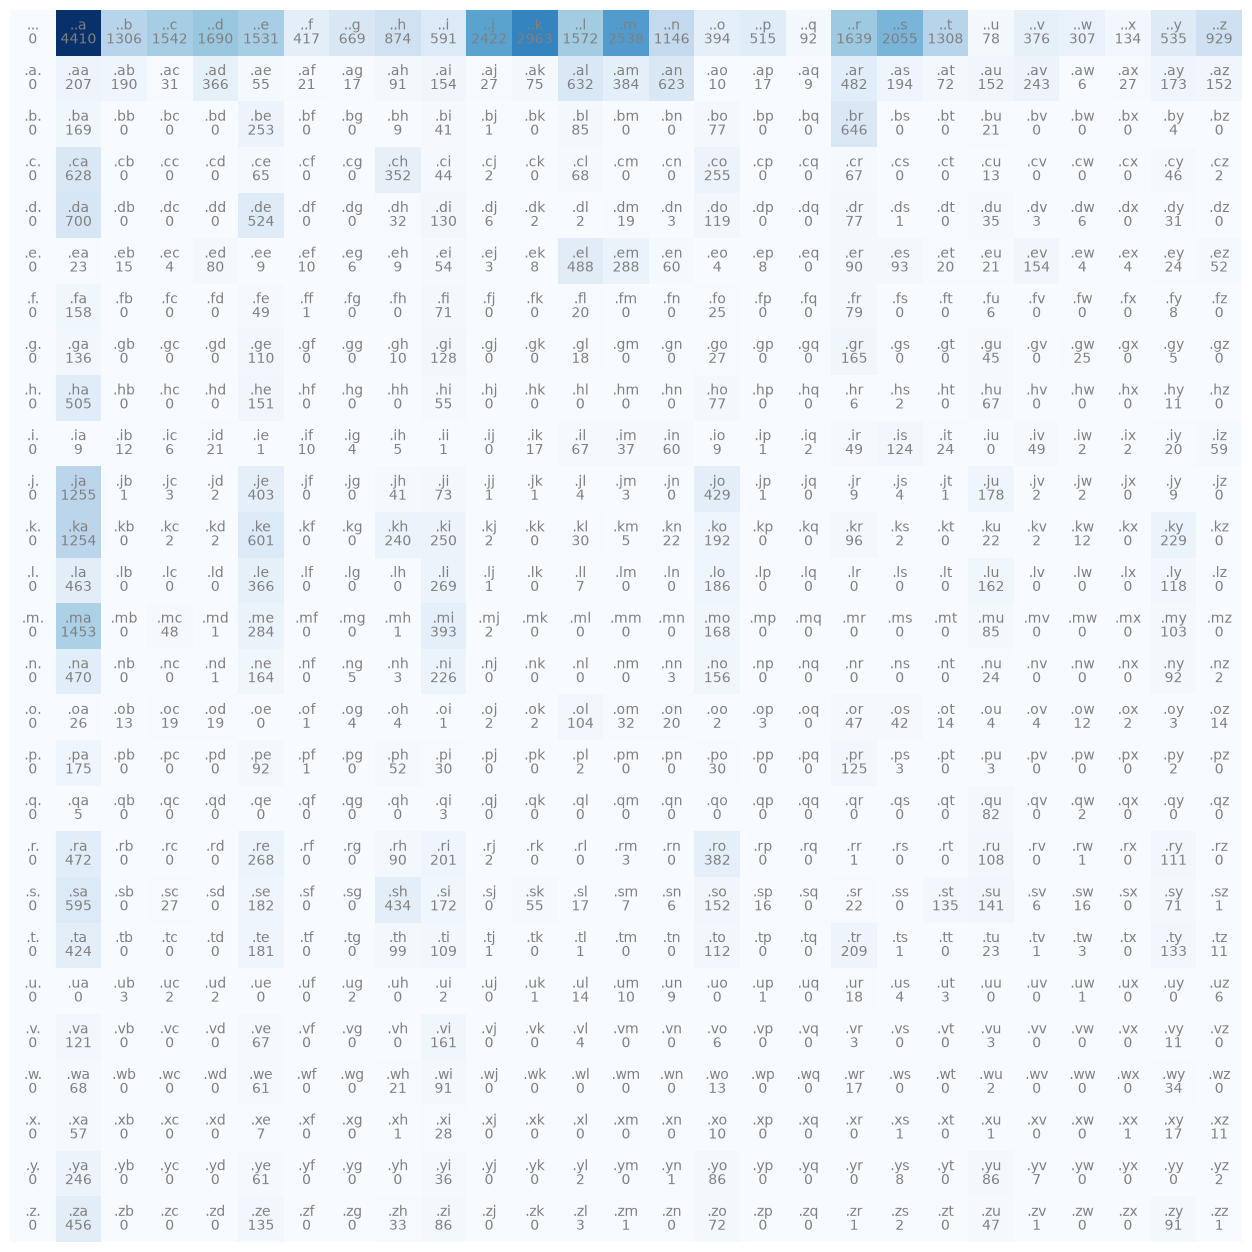

In [35]:
# first 27*27 tensor
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N[:27], cmap='Blues')

for i in range(27):
    for j in range(27):
        chstr = '.' + itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')

plt.axis('off');

In [36]:
# normalization
P = (N+1).float()
P /= P.sum(1, keepdims=True)
P.shape

torch.Size([729, 27])

In [37]:
# generate names
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix1 = 0
    while True:
        p = P[ix1]
        ix2 = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix2])
        if ix2 == 0:
            break
        ix1 = (ix1 % 27) * 27 + ix2
    print(''.join(out))

junide.
jakasid.
prelay.
adin.
kairritoper.
sathen.
sameia.
yanileniassibduinrwin.
lessiyanayla.
te.
